In [1]:
import pandas as pd, numpy as np
from sklearn.model_selection import train_test_split

url = "https://raw.githubusercontent.com/jbrownlee/Datasets/master/pima-indians-diabetes.data.csv"
cols = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
        "Insulin","BMI","DiabetesPedigreeFunction","Age","Outcome"]
df = pd.read_csv(url, names=cols)
df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]] = \
    df[["Glucose","BloodPressure","SkinThickness","Insulin","BMI"]].replace(0, np.nan)

X, y = df.drop(columns="Outcome"), df["Outcome"]
X_trainval, X_test, y_trainval, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=42)
X_train, X_val, y_train, y_val = train_test_split(
    X_trainval, y_trainval, test_size=0.25, stratify=y_trainval, random_state=42)

print("Train:", X_train.shape, "| Val:", X_val.shape, "| Test:", X_test.shape)

Train: (460, 8) | Val: (154, 8) | Test: (154, 8)


In [2]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score,
                             f1_score, confusion_matrix, roc_auc_score, brier_score_loss)

models = {
    "Baseline": DummyClassifier(strategy="most_frequent"),
    "LogReg": Pipeline([("imputer", SimpleImputer(strategy="median")),
                        ("scaler", StandardScaler()),
                        ("clf", LogisticRegression(max_iter=1000, random_state=42))]),
    "RF": Pipeline([("imputer", SimpleImputer(strategy="median")),
                    ("clf", RandomForestClassifier(n_estimators=300, random_state=42))]),
}
for m in models.values(): m.fit(X_train, y_train)

print("=== Threshold sweep on VALIDATION ===")
print("thr | Rec  | Prec | F1   | FN | FP")
for thr in [0.20,0.25,0.30,0.35,0.40,0.45,0.50]:
    p = models["RF"].predict_proba(X_val)[:,1]
    pred = (p >= thr).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_val, pred).ravel()
    print(f"{thr:.2f}| {recall_score(y_val,pred):.3f}| {precision_score(y_val,pred,zero_division=0):.3f}| {f1_score(y_val,pred):.3f}| {fn:2d} | {fp:2d}")

=== Threshold sweep on VALIDATION ===
thr | Rec  | Prec | F1   | FN | FP
0.20| 0.944| 0.520| 0.671|  3 | 47
0.25| 0.907| 0.551| 0.685|  5 | 40
0.30| 0.833| 0.592| 0.692|  9 | 31
0.35| 0.796| 0.623| 0.699| 11 | 26
0.40| 0.741| 0.667| 0.702| 14 | 20
0.45| 0.667| 0.655| 0.661| 18 | 19
0.50| 0.630| 0.708| 0.667| 20 | 14


In [3]:
THR = 0.30
print(f"=== FINAL TEST SET (thr={THR}) ===")
for name, m in models.items():
    proba = m.predict_proba(X_test)[:,1]
    pred = (proba >= THR).astype(int)
    tn,fp,fn,tp = confusion_matrix(y_test, pred).ravel()
    print(f"\n{name}: Acc={accuracy_score(y_test,pred):.3f}  Prec={precision_score(y_test,pred,zero_division=0):.3f}  "
          f"Rec={recall_score(y_test,pred):.3f}  F1={f1_score(y_test,pred):.3f}  "
          f"AUC={roc_auc_score(y_test,proba):.3f}  Brier={brier_score_loss(y_test,proba):.3f}  "
          f"FN={fn}  FP={fp}")

=== FINAL TEST SET (thr=0.3) ===

Baseline: Acc=0.649  Prec=0.000  Rec=0.000  F1=0.000  AUC=0.500  Brier=0.351  FN=54  FP=0

LogReg: Acc=0.747  Prec=0.606  Rec=0.796  F1=0.688  AUC=0.817  Brier=0.175  FN=11  FP=28

RF: Acc=0.708  Prec=0.560  Rec=0.778  F1=0.651  AUC=0.816  Brier=0.167  FN=12  FP=33


=== Mean |SHAP| ===
Glucose                     1.0560
BMI                         0.6708
Pregnancies                 0.2721
DiabetesPedigreeFunction    0.2232
BloodPressure               0.1282
Age                         0.1054
Insulin                     0.0744
SkinThickness               0.0521
dtype: float64


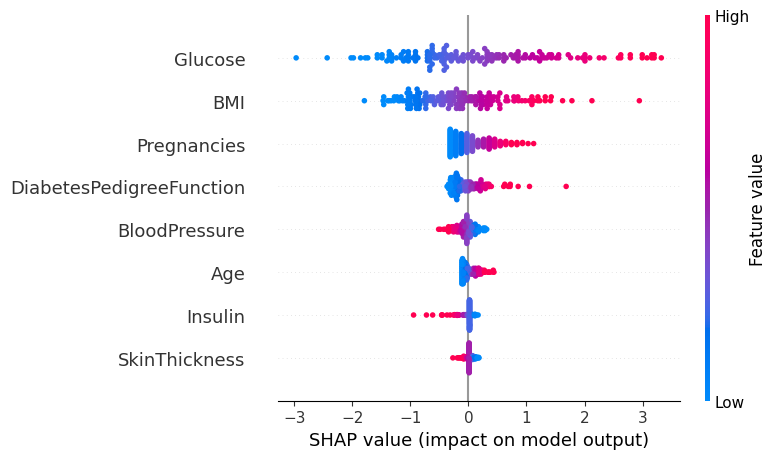


=== Age group analysis on TEST set ===
band    | n  | pos | TP | FN | FP | recall
21-30  | 85 |  16 | 10 |  6 | 15 | 0.62
30-40  | 30 |  20 | 16 |  4 |  3 | 0.80
40-50  | 24 |  12 | 12 |  0 |  6 | 1.00
50-100  | 15 |   6 |  5 |  1 |  4 | 0.83


In [4]:
import shap, joblib
logreg = models["LogReg"]
explainer = shap.LinearExplainer(logreg.named_steps["clf"],
    logreg.named_steps["scaler"].transform(logreg.named_steps["imputer"].transform(X_train))[:100])
X_test_imp = logreg.named_steps["imputer"].transform(X_test)
X_test_scaled = logreg.named_steps["scaler"].transform(X_test_imp)
sv = explainer.shap_values(X_test_scaled)
imp = pd.Series(np.abs(sv).mean(axis=0), index=X.columns).sort_values(ascending=False)
print("=== Mean |SHAP| ===")
print(imp.round(4))
shap.summary_plot(sv, X_test_scaled, feature_names=X.columns, show=True)

# --- Age group analysis ---
print("\n=== Age group analysis on TEST set ===")
test_age = X_test["Age"].values
test_pred = (logreg.predict_proba(X_test)[:,1] >= THR).astype(int)
y_test_arr = y_test.values
print("band    | n  | pos | TP | FN | FP | recall")
for lo, hi in [(21,30),(30,40),(40,50),(50,100)]:
    mask = (test_age >= lo) & (test_age < hi)
    n = mask.sum(); pos = y_test_arr[mask].sum()
    if n == 0: continue
    tp = ((test_pred[mask]==1) & (y_test_arr[mask]==1)).sum()
    fn = ((test_pred[mask]==0) & (y_test_arr[mask]==1)).sum()
    fp = ((test_pred[mask]==1) & (y_test_arr[mask]==0)).sum()
    rec = tp/(tp+fn) if (tp+fn)>0 else float('nan')
    print(f"{lo:2d}-{hi:2d}  | {n:2d} | {pos:3d} | {tp:2d} | {fn:2d} | {fp:2d} | {rec:.2f}")

In [5]:
logreg_final = Pipeline([("imputer", SimpleImputer(strategy="median")),
                         ("scaler", StandardScaler()),
                         ("clf", LogisticRegression(max_iter=1000, random_state=42))]).fit(X_trainval, y_trainval)
joblib.dump(logreg_final, "healthsignal_logreg.pkl")
print("Saved healthsignal_logreg.pkl")
from google.colab import files
files.download("healthsignal_logreg.pkl")

Saved healthsignal_logreg.pkl


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
import gradio as gr
import joblib
import numpy as np
import pandas as pd
import shap
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

MODEL = joblib.load("healthsignal_logreg.pkl")
IMPUTER = MODEL.named_steps["imputer"]
SCALER = MODEL.named_steps["scaler"]
CLF = MODEL.named_steps["clf"]
FEATURES = ["Pregnancies","Glucose","BloodPressure","SkinThickness",
            "Insulin","BMI","DiabetesPedigreeFunction","Age"]
THRESHOLD = 0.30

# LinearExplainer needs a background sample. Use the median-imputed mean of training-like data.
_bg = pd.DataFrame([{
    "Pregnancies":3,"Glucose":120,"BloodPressure":70,"SkinThickness":23,
    "Insulin":80,"BMI":32,"DiabetesPedigreeFunction":0.5,"Age":33
}])[FEATURES]
_bg_imp = IMPUTER.transform(_bg)
_bg_scaled = SCALER.transform(_bg_imp)
EXPLAINER = shap.LinearExplainer(CLF, _bg_scaled)


def predict(pregnancies, glucose, blood_pressure, skin_thickness,
            insulin, bmi, pedigree, age):
    if glucose < 40 or glucose > 400:
        return "⚠️ Glucose must be between 40–400 mg/dL.", None, ""
    if bmi < 10 or bmi > 70:
        return "⚠️ BMI must be between 10–70.", None, ""
    if age < 1 or age > 120:
        return "⚠️ Age must be between 1–120.", None, ""
    if blood_pressure < 30 or blood_pressure > 200:
        return "⚠️ Blood pressure must be between 30–200 mmHg.", None, ""
    if pregnancies < 0 or pregnancies > 20:
        return "⚠️ Pregnancies must be between 0–20.", None, ""
    if age < 21:
        return ("⚠️ This prototype was trained on women aged ≥21. "
                "Predictions for younger ages are outside the model's supported population.", None, "")

    row = pd.DataFrame([{
        "Pregnancies": pregnancies,
        "Glucose": glucose if glucose > 0 else np.nan,
        "BloodPressure": blood_pressure if blood_pressure > 0 else np.nan,
        "SkinThickness": skin_thickness if skin_thickness > 0 else np.nan,
        "Insulin": insulin if insulin > 0 else np.nan,
        "BMI": bmi if bmi > 0 else np.nan,
        "DiabetesPedigreeFunction": pedigree,
        "Age": age,
    }])[FEATURES]

    proba = MODEL.predict_proba(row)[0, 1]
    flagged = proba >= THRESHOLD

    if proba < 0.20:
        band, color = "LOW estimated model score", "#16a34a"
    elif proba < THRESHOLD:
        band, color = "MODERATE estimated model score", "#d97706"
    else:
        band, color = "ELEVATED estimated model score — recommend professional assessment", "#dc2626"

    result_md = f"""
<div style="padding:18px;border-radius:12px;background:#f8fafc;
            border-left:6px solid {color};">
  <div style="font-size:13px;color:#64748b;text-transform:uppercase;
              letter-spacing:1px;">Estimated model score</div>
  <div style="font-size:28px;font-weight:600;color:{color};
              margin:6px 0;">{proba*100:.1f}</div>
  <div style="font-size:15px;color:#0f172a;">{band}</div>
  <div style="font-size:12px;color:#334155;margin-top:10px;">
    Decision threshold: {THRESHOLD:.2f}. Screening flag:
    <b>{'YES' if flagged else 'NO'}</b>.
  </div>
  <div style="font-size:11px;color:#64748b;margin-top:8px;">
    This is a model score (0–100), not a clinical risk probability.
    It is not validated for diagnostic use.
  </div>
</div>
"""

    row_imp = IMPUTER.transform(row)
    row_scaled = SCALER.transform(row_imp)
    sv = EXPLAINER.shap_values(row_scaled)[0]

    fig, ax = plt.subplots(figsize=(7, 3.2))
    order = np.argsort(np.abs(sv))
    colors = ["#dc2626" if v > 0 else "#2563eb" for v in sv[order]]
    ax.barh(np.array(FEATURES)[order], sv[order], color=colors)
    ax.axvline(0, color="#94a3b8", linewidth=0.8)
    ax.set_xlabel("Contribution to model score (SHAP value)")
    ax.set_title("Why this score? (red = raises, blue = lowers). "
                 "Feature contributions describe model behavior, not medical causes.",
                 fontsize=9, loc="left")
    ax.spines[["top","right"]].set_visible(False)
    plt.tight_layout()

    top = pd.Series(np.abs(sv), index=FEATURES).sort_values(ascending=False)
    top3 = top.head(3)
    explain_lines = [
        f"**{feat}** — measured **{row.iloc[0][feat] if not pd.isna(row.iloc[0][feat]) else 'not provided'}**"
        + (" (raises score)" if sv[FEATURES.index(feat)] > 0 else " (lowers score)")
        for feat in top3.index
    ]
    explanation_md = ("### Top contributing factors\n\n"
                      + "\n".join(f"- {l}" for l in explain_lines)
                      + "\n\n*These contributions describe how the model behaves. "
                        "They are not medical causes.*")

    return result_md, fig, explanation_md


with gr.Blocks(title="HealthSignal AI") as demo:
    gr.Markdown("""
    # HealthSignal AI
    ### Intelligent Insights for Earlier Health Awareness

    Community health workers: enter routine measurements to estimate diabetes
    model score and identify individuals who may benefit from professional assessment.

    > ⚠️ **This project is a prototype and is not medical advice.**
    > It does not diagnose diabetes and does not replace a clinician.
    """)
    gr.Markdown("""
    > ⚠️ **Trained on women of Pima Indigenous descent, aged ≥21, 1990s data.**
    > **Not validated for males, children, or any other population group.**
    > This tool is a **screening-awareness prototype for community health workers** —
    > it does not replace professional assessment and is not a diagnostic device.
    """)

    with gr.Row():
        with gr.Column(scale=1):
            gr.Markdown("### Health measurements")
            pregnancies = gr.Number(label="Pregnancies", value=2, precision=0)
            glucose     = gr.Number(label="Glucose (mg/dL)", value=120)
            bp          = gr.Number(label="Blood Pressure (mmHg)", value=70)
            skin        = gr.Number(label="Skin Thickness (mm, 0 = unknown)", value=0)
            insulin     = gr.Number(label="Insulin (μU/mL, 0 = unknown)", value=0)
            bmi         = gr.Number(label="BMI", value=28.5)
            pedigree    = gr.Number(label="Diabetes Pedigree Function", value=0.5)
            age         = gr.Number(label="Age (years)", value=35)
            btn = gr.Button("Estimate model score", variant="primary", size="lg")

        with gr.Column(scale=2):
            out_result = gr.HTML()
            out_expl   = gr.Markdown()
            out_plot   = gr.Plot()

    btn.click(predict,
              inputs=[pregnancies, glucose, bp, skin, insulin, bmi, pedigree, age],
              outputs=[out_result, out_plot, out_expl])

    with gr.Accordion("About this model & its limitations", open=False):
        gr.Markdown("""
        **Model:** Logistic Regression (interpretable, linear), trained on the Pima Indians Diabetes dataset (768 samples).
        **Final test F1:** 0.688, recall 0.796, precision 0.606, FN 11, FP 28 (threshold 0.30).
        **Why not Random Forest?** Logistic Regression outperformed RF on recall, precision, and F1 in the final held-out test set, and its coefficients are directly interpretable.

        **Limitations you must know:**
        - Trained on **women of Pima Indigenous descent** aged ≥21. Not validated for males, children, or other ethnic groups.
        - Data collected in the **1990s**; diagnostic criteria may have shifted.
        - **Insulin and Skin Thickness are ~30–49% missing** in the source data — SHAP contributions from these features are unreliable.
        - The model score is **not a calibrated clinical probability**.
        - Performance varies by age band; subgroup sample sizes are too small for statistical conclusions.
        - **This is a screening-awareness prototype, not a diagnostic tool.**

        **This project is a prototype and is not medical advice.**
        """)

demo.launch(share=True)

Colab notebook detected. To show errors in colab notebook, set debug=True in launch()
* Running on public URL: https://d3181244a27741ce84.gradio.live

This share link is temporary and will last for up to 1 week (best effort). For free permanent hosting and GPU upgrades, run `gradio deploy` from the terminal in the working directory to deploy to Hugging Face Spaces (https://huggingface.co/spaces)
